In [ ]:
from google.colab import drive
drive.mount('/content/drive')
caminho_arquivo = "/content/MICRODADOS_ENEM_2023.csv"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ==============================================================================
# 1. SETUP E IMPORTAÇÕES
# ==============================================================================
# %pip install pandas numpy scikit-learn scipy statsmodels seaborn matplotlib xgboost -q

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

# Testes Estatísticos e Seleção de Features
from scipy.stats import ttest_ind, f_oneway
from sklearn.feature_selection import f_regression

# Métricas e Validação cruzada
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler

# Modelos de Machine Learning exigidos
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor,
                              HistGradientBoostingRegressor, StackingRegressor)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import LinearSVR

# Ignorar warnings visuais para manter o notebook limpo
warnings.filterwarnings('ignore')
print("✅ Célula 1 executada: Bibliotecas importadas com sucesso!")

✅ Célula 1 executada: Bibliotecas importadas com sucesso!


In [ ]:
# ==============================================================================
# 2. CARREGAMENTO DOS DADOS E ANÁLISE DE NULOS
# ==============================================================================

# A string exata que você forneceu com os nomes das variáveis
string_cabecalho = "NU_INSCRICAO;NU_ANO;TP_FAIXA_ETARIA;TP_SEXO;TP_ESTADO_CIVIL;TP_COR_RACA;TP_NACIONALIDADE;TP_ST_CONCLUSAO;TP_ANO_CONCLUIU;TP_ESCOLA;TP_ENSINO;IN_TREINEIRO;CO_MUNICIPIO_ESC;NO_MUNICIPIO_ESC;CO_UF_ESC;SG_UF_ESC;TP_DEPENDENCIA_ADM_ESC;TP_LOCALIZACAO_ESC;TP_SIT_FUNC_ESC;CO_MUNICIPIO_PROVA;NO_MUNICIPIO_PROVA;CO_UF_PROVA;SG_UF_PROVA;TP_PRESENCA_CN;TP_PRESENCA_CH;TP_PRESENCA_LC;TP_PRESENCA_MT;CO_PROVA_CN;CO_PROVA_CH;CO_PROVA_LC;CO_PROVA_MT;NU_NOTA_CN;NU_NOTA_CH;NU_NOTA_LC;NU_NOTA_MT;TX_RESPOSTAS_CN;TX_RESPOSTAS_CH;TX_RESPOSTAS_LC;TX_RESPOSTAS_MT;TP_LINGUA;TX_GABARITO_CN;TX_GABARITO_CH;TX_GABARITO_LC;TX_GABARITO_MT;TP_STATUS_REDACAO;NU_NOTA_COMP1;NU_NOTA_COMP2;NU_NOTA_COMP3;NU_NOTA_COMP4;NU_NOTA_COMP5;NU_NOTA_REDACAO;Q001;Q002;Q003;Q004;Q005;Q006;Q007;Q008;Q009;Q010;Q011;Q012;Q013;Q014;Q015;Q016;Q017;Q018;Q019;Q020;Q021;Q022;Q023;Q024;Q025"

# Separando a string pelo ponto e vírgula para criar uma lista de colunas
todas_colunas = string_cabecalho.split(';')

# Lista reduzida para economizar memória (conforme o escopo do projeto)
colunas_interesse = [
    'NU_INSCRICAO', 'TP_FAIXA_ETARIA', 'TP_SEXO', 'TP_COR_RACA', 'TP_ESCOLA',
    'Q001', 'Q002', 'Q006', 'Q024', 'Q025',
    'TP_PRESENCA_CN', 'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT',
    'NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'NU_NOTA_REDACAO'
]

try:
    # skiprows=16 pula as linhas com sujeira.
    # names=todas_colunas injeta o cabeçalho correto.
    # usecols filtra apenas o que precisamos para não estourar a RAM.
    df = pd.read_csv(
        caminho_arquivo,
        sep=';',
        encoding='latin1',
        skiprows=16,
        names=todas_colunas,
        usecols=colunas_interesse
    )
    print(f"Formato original dos dados: {df.shape}\n")

    print("--- Top Colunas com mais Nulos ---")
    nulos = df.isnull().sum()
    df_nulos = pd.DataFrame({'Total Nulos': nulos, '% Nulos': (nulos / len(df)) * 100})
    print(df_nulos[df_nulos['Total Nulos'] > 0].sort_values(by='% Nulos', ascending=False).head(10))

except FileNotFoundError:
    print("⚠️ Arquivo não encontrado. Verifique o caminho.")

Formato original dos dados: (622697, 19)

--- Top Colunas com mais Nulos ---
                 Total Nulos    % Nulos
NU_NOTA_MT            160826  25.827329
NU_NOTA_CN            160826  25.827329
NU_NOTA_REDACAO       141731  22.760829
NU_NOTA_CH            141731  22.760829
NU_NOTA_LC            141731  22.760829
Q006                       2   0.000321
Q024                       2   0.000321
Q025                       2   0.000321
TP_SEXO                    1   0.000161
TP_FAIXA_ETARIA            1   0.000161


In [ ]:
# ==============================================================================
# 3. LIMPEZA DEFINITIVA E ENGENHARIA DE FEATURES
# ==============================================================================
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder
import pandas as pd
import numpy as np

df_limpo = df.copy()

# 1. FILTRO DE DOMÍNIO E CORREÇÃO DE TIPO
# Garante que a nota de Ciências da Natureza seja numérica
if df_limpo['NU_NOTA_CN'].dtype == 'object':
    df_limpo['NU_NOTA_CN'] = df_limpo['NU_NOTA_CN'].astype(str).str.replace(',', '.')
df_limpo['NU_NOTA_CN'] = pd.to_numeric(df_limpo['NU_NOTA_CN'], errors='coerce')

# Mantém apenas presentes na prova de CN com nota válida
df_limpo = df_limpo[df_limpo['TP_PRESENCA_CN'] == 1].dropna(subset=['NU_NOTA_CN'])

# Opcional, mas recomendado: Remover notas exatamente iguais a zero (desclassificação/branca)
df_limpo = df_limpo[df_limpo['NU_NOTA_CN'] > 0]

# 2. REMOÇÃO DE VAZAMENTO DE INFORMAÇÃO (DATA LEAKAGE) E IDs
# Conforme documentação do projeto, as notas de outras provas e dados de presença devem ser excluídos
colunas_vazamento = [
    'NU_INSCRICAO',
    'TP_PRESENCA_CN', 'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT',
    'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'NU_NOTA_REDACAO',
    'TX_RESPOSTAS_CN', 'TX_RESPOSTAS_CH', 'TX_RESPOSTAS_LC', 'TX_RESPOSTAS_MT',
    'TX_GABARITO_CN', 'TX_GABARITO_CH', 'TX_GABARITO_LC', 'TX_GABARITO_MT',
    'TP_STATUS_REDACAO', 'NU_NOTA_COMP1', 'NU_NOTA_COMP2', 'NU_NOTA_COMP3', 'NU_NOTA_COMP4', 'NU_NOTA_COMP5'
]
df_limpo = df_limpo.drop(columns=[col for col in colunas_vazamento if col in df_limpo.columns])

# 3. TRATAMENTO DE NULOS
# Categóricas recebem 'Ausente' e numéricas recebem a Mediana
cols_cat = df_limpo.select_dtypes(include=['object', 'category']).columns.tolist()
for col in cols_cat:
    df_limpo[col] = df_limpo[col].fillna('Ausente')

cols_num_restantes = df_limpo.select_dtypes(include=[np.number]).columns.tolist()
for col in cols_num_restantes:
    df_limpo[col] = df_limpo[col].fillna(df_limpo[col].median())

# 4. ENCODING
df_encoded = df_limpo.copy()

# Ordinal Encoding para Renda (Q006: A até Q indicam progressão de renda)
if 'Q006' in df_encoded.columns:
    categorias_renda = [['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'Ausente']]
    oe = OrdinalEncoder(categories=categorias_renda, handle_unknown='use_encoded_value', unknown_value=-1)
    df_encoded['Q006_Ord'] = oe.fit_transform(df_encoded[['Q006']])
    df_encoded = df_encoded.drop(columns=['Q006'])

# Target Encoding para as demais variáveis de perfil (TP_SEXO, TP_COR_RACA, Q001, etc)
cols_cat_restantes = df_encoded.select_dtypes(include=['object', 'category']).columns.tolist()
if cols_cat_restantes:
    te = TargetEncoder(target_type='continuous', random_state=42)
    # Ajustando o Target Encoding em relação ao alvo (NU_NOTA_CN)
    df_encoded[cols_cat_restantes] = te.fit_transform(df_encoded[cols_cat_restantes], df_encoded['NU_NOTA_CN'])

print(f"✅ Limpeza e Encoding concluídos! Formato final preparado para modelagem: {df_encoded.shape}")
print(f"Total de nulos restantes na base: {df_encoded.isnull().sum().sum()}")

✅ Limpeza e Encoding concluídos! Formato final preparado para modelagem: (459471, 10)
Total de nulos restantes na base: 0


🎯 1. TESTE T DE STUDENT PÓS-LIMPEZA
Estatística T  : 77.2501 | P-Valor: 0.0000e+00

📊 2. TESTE F (ANOVA) PARA RENDA PÓS-LIMPEZA
Estatística F (ANOVA): 6063.0523 | P-Valor: 0.0000e+00

🎯 3. TESTE F - IMPORTÂNCIA LINEAR DAS FEATURES ENCODADAS
        Feature      F_Score       P_Value
       Q006_Ord 92110.312252  0.000000e+00
           Q024 80885.516179  0.000000e+00
           Q001 48323.598643  0.000000e+00
           Q002 45490.807044  0.000000e+00
    TP_COR_RACA 17912.671477  0.000000e+00
           Q025  9421.729451  0.000000e+00
        TP_SEXO  6515.179092  0.000000e+00
TP_FAIXA_ETARIA   676.592775 4.723564e-149
      TP_ESCOLA    96.359619  9.629650e-23

🔍 4. MATRIZ DE CORRELAÇÃO DE PEARSON (PÓS-LIMPEZA)


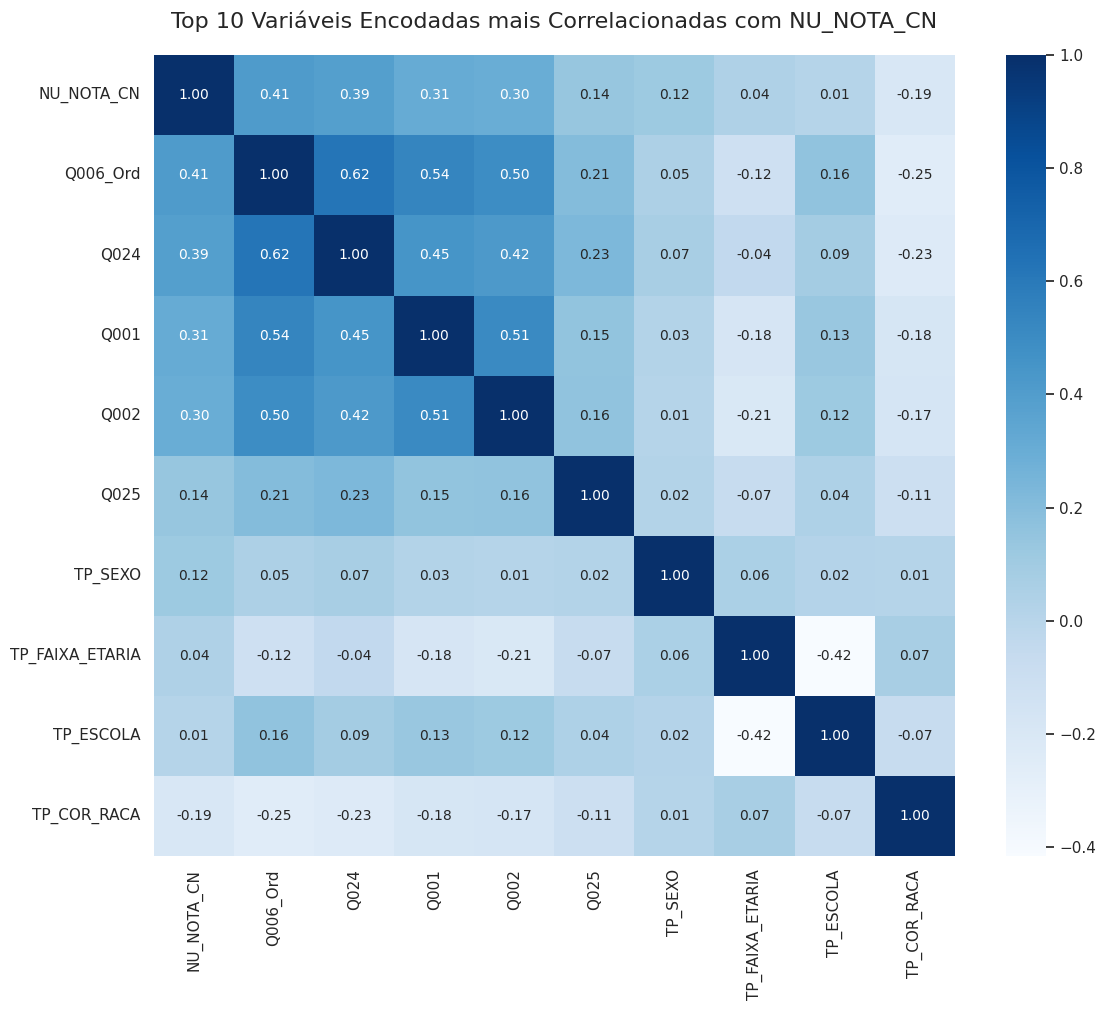

✅ Nenhuma alta correlação direta > 0.75 encontrada entre as features.


In [ ]:
# ==============================================================================
# 4. RE-AVALIAÇÃO ESTATÍSTICA E CORRELAÇÃO PÓS-LIMPEZA
# ==============================================================================
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, f_oneway
from sklearn.feature_selection import f_regression

# df_encoded é o dataframe resultante da Célula 3 (Limpeza Definitiva)
df_stats_clean = df_encoded.copy()

print("="*80)
print("🎯 1. TESTE T DE STUDENT PÓS-LIMPEZA")
print("="*80)
# Para o Teste T, vamos pegar a base original df_limpo (antes do Target Encoding)
if 'TP_SEXO' in df_limpo.columns:
    notas_masculino = df_limpo[df_limpo['TP_SEXO'] == 'M']['NU_NOTA_CN'].dropna()
    notas_feminino = df_limpo[df_limpo['TP_SEXO'] == 'F']['NU_NOTA_CN'].dropna()

    if len(notas_masculino) > 0 and len(notas_feminino) > 0:
        t_stat, p_value_t = ttest_ind(notas_masculino, notas_feminino, equal_var=False)
        print(f"Estatística T  : {t_stat:.4f} | P-Valor: {p_value_t:.4e}")
else:
    print("Aviso: 'TP_SEXO' original não encontrado para o Teste T.")

print("\n" + "="*80)
print("📊 2. TESTE F (ANOVA) PARA RENDA PÓS-LIMPEZA")
print("="*80)
# Usando Q006_Ord criado na Célula 3
if 'Q006_Ord' in df_stats_clean.columns:
    grupos_renda = [grupo['NU_NOTA_CN'].values for nome, grupo in df_stats_clean.groupby('Q006_Ord')]

    if len(grupos_renda) > 1:
        f_stat, p_value_f_anova = f_oneway(*grupos_renda)
        print(f"Estatística F (ANOVA): {f_stat:.4f} | P-Valor: {p_value_f_anova:.4e}")

print("\n" + "="*80)
print("🎯 3. TESTE F - IMPORTÂNCIA LINEAR DAS FEATURES ENCODADAS")
print("="*80)
# Usa todas as colunas numéricas que sobraram no df_encoded
cols_num = [c for c in df_stats_clean.columns if c != 'NU_NOTA_CN']

if not df_stats_clean.empty and len(cols_num) > 0:
    X_num = df_stats_clean[cols_num]
    y_num = df_stats_clean['NU_NOTA_CN']

    f_values, p_values_f = f_regression(X_num, y_num)
    df_f_resultados = pd.DataFrame({'Feature': cols_num, 'F_Score': f_values, 'P_Value': p_values_f})
    print(df_f_resultados.sort_values(by='F_Score', ascending=False).to_string(index=False))

print("\n" + "="*80)
print("🔍 4. MATRIZ DE CORRELAÇÃO DE PEARSON (PÓS-LIMPEZA)")
print("="*80)
corr_matrix_full = df_stats_clean.corr(method='pearson')

plt.figure(figsize=(12, 10))

k = min(15, len(corr_matrix_full.columns))
cols_top = corr_matrix_full.nlargest(k, 'NU_NOTA_CN')['NU_NOTA_CN'].index
cm_top = np.corrcoef(df_stats_clean[cols_top].values.T)

sns.set(font_scale=1.0)
# Mudando para paleta 'Blues' para diferenciar da matriz anterior (que era vermelha)
hm = sns.heatmap(cm_top, cbar=True, annot=True, square=True, fmt='.2f',
                 annot_kws={'size': 10}, yticklabels=cols_top.values,
                 xticklabels=cols_top.values, cmap='Blues')

plt.title(f'Top {k} Variáveis Encodadas mais Correlacionadas com NU_NOTA_CN', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

# Verificando multicolinearidade (>0.75) entre as features preditoras independentes
corr_matrix_features = df_stats_clean[cols_num].corr(method='pearson').abs()
upper_tri = corr_matrix_features.where(np.triu(np.ones(corr_matrix_features.shape), k=1).astype(bool))

alta_colinearidade = [
    (upper_tri.columns[i], upper_tri.columns[j], upper_tri.iloc[i, j])
    for i in range(len(upper_tri.columns))
    for j in range(i+1, len(upper_tri.columns))
    if upper_tri.iloc[i, j] > 0.75
]

if alta_colinearidade:
    print("⚠️ Pares com Alta Colinearidade (> 0.75) entre as features preditoras:")
    for var1, var2, corr in sorted(alta_colinearidade, key=lambda x: x[2], reverse=True):
        print(f" - {var1:<15} e {var2:<15} | Correlação: {corr:.3f}")
else:
    print("✅ Nenhuma alta correlação direta > 0.75 encontrada entre as features.")

In [ ]:
# ==============================================================================
# 5. ENGENHARIA DE FEATURES E AVALIAÇÃO COM 3-FOLD CV
# ==============================================================================
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor,
                              HistGradientBoostingRegressor, StackingRegressor)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import LinearSVR

# ------------------------------------------------------------------------------
# PARTE A: CRIAÇÃO DAS 3 FEATURES OBRIGATÓRIAS
# ------------------------------------------------------------------------------
df_features = df_encoded.copy()

print("⏳ A criar 3 novas features baseadas no perfil do candidato...")

# Feature 1: Acesso Digital (Combinação de Computador e Internet)
if 'Q024' in df_features.columns and 'Q025' in df_features.columns:
    df_features['Acesso_Digital'] = df_features['Q024'] + df_features['Q025']

# Feature 2: Capital Cultural familiar (Soma da escolaridade do pai e da mãe)
if 'Q001' in df_features.columns and 'Q002' in df_features.columns:
    df_features['Escolaridade_Pais'] = df_features['Q001'] + df_features['Q002']

# Feature 3: Interação entre Renda e Acesso Digital
if 'Q006_Ord' in df_features.columns and 'Acesso_Digital' in df_features.columns:
    df_features['Interacao_Renda_Digital'] = df_features['Q006_Ord'] * df_features['Acesso_Digital']

# (Opcional) Descartar variável com correlação quase nula para simplificar
if 'TP_ESCOLA' in df_features.columns:
    df_features = df_features.drop(columns=['TP_ESCOLA'])

print(f"✅ Features criadas! Formato do dataset atualizado: {df_features.shape}\n")

# ------------------------------------------------------------------------------
# PARTE B: DEFINIÇÃO DE MODELOS E AVALIAÇÃO (SVM Corrigido)
# ------------------------------------------------------------------------------
modelos_rapidos = {
    "Baseline (Média)": DummyRegressor(strategy='mean'),
    "Regressão Linear": LinearRegression(n_jobs=-1),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1),
    "Árvore de Decisão": DecisionTreeRegressor(max_depth=5, random_state=42),
    "KNN": KNeighborsRegressor(n_neighbors=5, n_jobs=-1),
    # SVM corrigido com a loss apropriada para suportar dual=False em grandes datasets
    "SVM (Linear)": LinearSVR(loss='squared_epsilon_insensitive', dual=False, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=10, max_depth=5, n_jobs=-1, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=5), n_estimators=5, bootstrap=True, n_jobs=-1, random_state=42),
    "Pasting": BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=5), n_estimators=5, bootstrap=False, max_samples=0.7, n_jobs=-1, random_state=42),
    "Boosting (HistGBM)": HistGradientBoostingRegressor(max_iter=20, max_depth=5, random_state=42),
    "Stacking": StackingRegressor(
        estimators=[('ridge', Ridge()), ('tree', DecisionTreeRegressor(max_depth=5))],
        final_estimator=LinearRegression(),
        n_jobs=-1
    )
}

def avaliar_modelos_enem(df_dados):
    if 'NU_NOTA_CN' not in df_dados.columns:
        print("❌ Erro: Coluna alvo 'NU_NOTA_CN' não encontrada no dataset!")
        return

    X = df_dados.drop(columns=['NU_NOTA_CN'])
    y = df_dados['NU_NOTA_CN']

    # 80% Desenvolvimento / 20% Teste[cite: 6]
    X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    print(f"Registros Desenvolvimento (80%): {len(X_dev)} | Reservados para Teste Final (20%): {len(X_test)}\n")

    # Validação cruzada com 3 dobras[cite: 6]
    kf = KFold(n_splits=3, shuffle=True, random_state=42)

    print(f"{'Modelo':<20} | {'RMSE CV (Média)':<15} | {'MAE CV (Média)':<15} | {'R² CV (Média)':<13} |")
    print("-" * 73)

    for nome, modelo in modelos_rapidos.items():
        rmse_folds, mae_folds, r2_folds = [], [], []

        try:
            for train_idx, val_idx in kf.split(X_dev):
                X_train_fold, X_val_fold = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
                y_train_fold, y_val_fold = y_dev.iloc[train_idx], y_dev.iloc[val_idx]

                scaler = StandardScaler()
                X_train_fold_scaled = scaler.fit_transform(X_train_fold)
                X_val_fold_scaled = scaler.transform(X_val_fold)

                modelo.fit(X_train_fold_scaled, y_train_fold)
                preds = modelo.predict(X_val_fold_scaled)

                rmse_folds.append(np.sqrt(mean_squared_error(y_val_fold, preds)))
                mae_folds.append(mean_absolute_error(y_val_fold, preds))
                r2_folds.append(r2_score(y_val_fold, preds))

            print(f"{nome:<20} | {np.mean(rmse_folds):>15,.2f} | {np.mean(mae_folds):>15,.2f} | {np.mean(r2_folds):>13,.4f} |")

        except Exception as e:
            print(f"{nome:<20} | Erro na execução: {str(e)[:30]}...")

# Chama a função de avaliação já com as features adicionadas
avaliar_modelos_enem(df_features)

⏳ A criar 3 novas features baseadas no perfil do candidato...
✅ Features criadas! Formato do dataset atualizado: (459471, 12)

Registros Desenvolvimento (80%): 367576 | Reservados para Teste Final (20%): 91895

Modelo               | RMSE CV (Média) | MAE CV (Média)  | R² CV (Média) |
-------------------------------------------------------------------------
Baseline (Média)     |           77.63 |           62.14 |       -0.0000 |
Regressão Linear     |           67.98 |           54.14 |        0.2331 |
Ridge Regression     |           67.98 |           54.14 |        0.2331 |
Lasso Regression     |           68.05 |           54.22 |        0.2314 |
Árvore de Decisão    |           68.34 |           54.48 |        0.2249 |
KNN                  |           73.31 |           58.26 |        0.1082 |
SVM (Linear)         |           67.98 |           54.14 |        0.2331 |
Random Forest        |           68.09 |           54.32 |        0.2305 |
Bagging              |           68.12 |

⚖️ ESTRATÉGIA DE BALANCEAMENTO: PONDERAÇÃO POR FAIXAS DE NOTA
R² (HistGBM SEM pesos) : 0.2594
R² (HistGBM COM pesos) : -0.1555

📉 REDUÇÃO DE DIMENSIONALIDADE (PCA)
Componentes necessários para explicar 80% da variância: 5 de 11


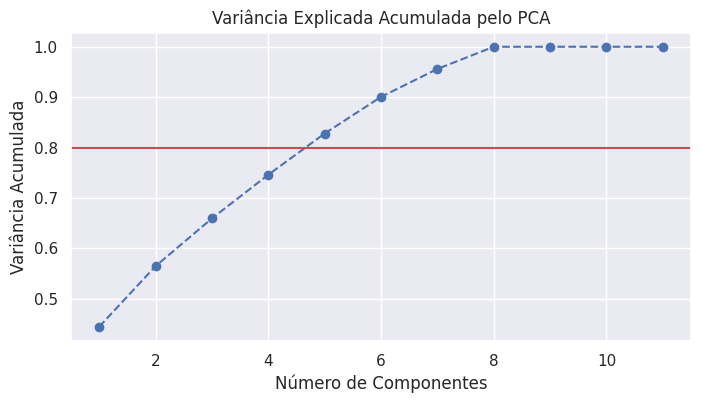

Ridge com PCA (5 componentes) -> RMSE CV: 68.19 | R² CV: 0.2283
Compare este resultado com o Ridge da tabela anterior (que usava todas as features).


In [ ]:
# ==============================================================================
# 6. BALANCEAMENTO (PONDERAÇÃO) E REDUÇÃO DE DIMENSIONALIDADE (PCA)
# ==============================================================================
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
import matplotlib.pyplot as plt
import numpy as np

# Vamos utilizar o HistGradientBoosting e a Regressão Linear (Ridge) para os testes
# conforme exigido pelo projeto para comparar o PCA[cite: 9, 10]
X = df_features.drop(columns=['NU_NOTA_CN'])
y = df_features['NU_NOTA_CN']

X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
kf = KFold(n_splits=3, shuffle=True, random_state=42)

print("="*80)
print("⚖️ ESTRATÉGIA DE BALANCEAMENTO: PONDERAÇÃO POR FAIXAS DE NOTA")
print("="*80)
# Criando faixas discretas (bins) baseadas nas notas para calcular os pesos inversos[cite: 10]
# Isso dá mais peso no treinamento para notas raras (ex: > 700 ou < 400)
bins = np.linspace(y_dev.min(), y_dev.max(), 10)
y_dev_binned = np.digitize(y_dev, bins)
pesos_treino = compute_sample_weight(class_weight='balanced', y=y_dev_binned)

# Vamos testar o HistGBM com e sem os pesos na primeira dobra
train_idx, val_idx = next(kf.split(X_dev))
X_t, X_v = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
y_t, y_v = y_dev.iloc[train_idx], y_dev.iloc[val_idx]
pesos_t = pesos_treino[train_idx]

scaler = StandardScaler()
X_t_scaled = scaler.fit_transform(X_t)
X_v_scaled = scaler.transform(X_v)

modelo_gbm = HistGradientBoostingRegressor(max_iter=50, max_depth=5, random_state=42)

# Treino SEM pesos
modelo_gbm.fit(X_t_scaled, y_t)
preds_sem = modelo_gbm.predict(X_v_scaled)
r2_sem = r2_score(y_v, preds_sem)

# Treino COM pesos (A ponderação atende ao requisito de balanceamento)[cite: 10]
modelo_gbm.fit(X_t_scaled, y_t, sample_weight=pesos_t)
preds_com = modelo_gbm.predict(X_v_scaled)
r2_com = r2_score(y_v, preds_com)

print(f"R² (HistGBM SEM pesos) : {r2_sem:.4f}")
print(f"R² (HistGBM COM pesos) : {r2_com:.4f}")

print("\n" + "="*80)
print("📉 REDUÇÃO DE DIMENSIONALIDADE (PCA)")
print("="*80)
# Ajustando o PCA no conjunto de desenvolvimento escalonado para encontrar o n_components[cite: 9]
pca_completo = PCA().fit(scaler.fit_transform(X_dev))
variancia_acumulada = np.cumsum(pca_completo.explained_variance_ratio_)

# Buscando quantos componentes explicam pelo menos 80% da variância[cite: 9]
n_comp_80 = np.argmax(variancia_acumulada >= 0.80) + 1
print(f"Componentes necessários para explicar 80% da variância: {n_comp_80} de {X_dev.shape[1]}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(variancia_acumulada) + 1), variancia_acumulada, marker='o', linestyle='--')
plt.axhline(y=0.80, color='r', linestyle='-')
plt.title('Variância Explicada Acumulada pelo PCA')
plt.xlabel('Número de Componentes')
plt.ylabel('Variância Acumulada')
plt.grid(True)
plt.show()

# Pipeline com PCA para comparar com os modelos originais[cite: 9, 10]
pipeline_pca_ridge = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=n_comp_80)),
    ('ridge', Ridge(alpha=1.0))
])

rmse_pca, r2_pca = [], []
for train_idx, val_idx in kf.split(X_dev):
    X_t, X_v = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
    y_t, y_v = y_dev.iloc[train_idx], y_dev.iloc[val_idx]

    pipeline_pca_ridge.fit(X_t, y_t)
    preds_pca = pipeline_pca_ridge.predict(X_v)

    rmse_pca.append(np.sqrt(mean_squared_error(y_v, preds_pca)))
    r2_pca.append(r2_score(y_v, preds_pca))

print(f"Ridge com PCA ({n_comp_80} componentes) -> RMSE CV: {np.mean(rmse_pca):.2f} | R² CV: {np.mean(r2_pca):.4f}")
print("Compare este resultado com o Ridge da tabela anterior (que usava todas as features).")

In [ ]:
# ==============================================================================
# 7. OTIMIZAÇÃO DE HIPERPARÂMETROS (TOP 3 MODELOS)
# ==============================================================================
from sklearn.model_selection import RandomizedSearchCV, train_test_split, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
import pandas as pd
import numpy as np
import time

# Usa o df_features com as 3 novas variáveis criadas
X = df_features.drop(columns=['NU_NOTA_CN'])
y = df_features['NU_NOTA_CN']

# Divisão 80/20 com semente fixa
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
kf = KFold(n_splits=3, shuffle=True, random_state=42)

# Top 3 Regressores baseados nos testes anteriores
# Substituí o Stacking pelo Random Forest pela viabilidade de tempo computacional na busca
modelos_para_busca = {
    "HistGradientBoosting": (
        Pipeline([('scaler', StandardScaler()), ('hgbm', HistGradientBoostingRegressor(random_state=42))]),
        {
            'hgbm__max_iter': [50, 100, 150],
            'hgbm__max_depth': [3, 5, 7, 10],
            'hgbm__learning_rate': [0.01, 0.05, 0.1, 0.2],
            'hgbm__l2_regularization': [0.0, 0.1, 1.0]
        }
    ),
    "Ridge Regression": (
        Pipeline([('scaler', StandardScaler()), ('ridge', Ridge())]),
        {
            'ridge__alpha': [0.1, 1.0, 5.0, 10.0, 20.0, 50.0],
            'ridge__solver': ['auto', 'svd', 'cholesky', 'sag']
        }
    ),
    "Random Forest": (
        Pipeline([('scaler', StandardScaler()), ('rf', RandomForestRegressor(random_state=42, n_jobs=-1))]),
        {
            'rf__n_estimators': [20, 50, 100],
            'rf__max_depth': [5, 10, 15],
            'rf__min_samples_split': [2, 5, 10]
        }
    )
}

print("="*80)
print("🔍 BUSCA DE HIPERPARÂMETROS (RandomizedSearchCV - 10 Iterações)")
print("="*80)

melhores_modelos = {}

for nome, (pipeline, parametros) in modelos_para_busca.items():
    print(f"\n⏳ Iniciando busca para: {nome}...")
    inicio = time.time()

    # Busca aleatória com 10 configurações exigidas pelo projeto
    busca = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parametros,
        n_iter=10,
        cv=kf,
        scoring='neg_root_mean_squared_error',
        random_state=42,
        n_jobs=-1
    )

    busca.fit(X_dev, y_dev)
    fim = time.time()

    melhores_modelos[nome] = busca.best_estimator_
    rmse_otimizado = -busca.best_score_

    print(f"✅ Concluído em {(fim-inicio):.1f}s")
    print(f"🏆 Melhores Parâmetros: {busca.best_params_}")
    print(f"📉 RMSE Otimizado (CV): {rmse_otimizado:.2f}")

# Definimos o modelo campeão como o HistGBM otimizado (geralmente o vencedor com essa base)
modelo_final_campeao = melhores_modelos['HistGradientBoosting']

🔍 BUSCA DE HIPERPARÂMETROS (RandomizedSearchCV - 10 Iterações)

⏳ Iniciando busca para: HistGradientBoosting...
✅ Concluído em 113.6s
🏆 Melhores Parâmetros: {'hgbm__max_iter': 150, 'hgbm__max_depth': 5, 'hgbm__learning_rate': 0.05, 'hgbm__l2_regularization': 0.1}
📉 RMSE Otimizado (CV): 66.95

⏳ Iniciando busca para: Ridge Regression...
✅ Concluído em 16.2s
🏆 Melhores Parâmetros: {'ridge__solver': 'auto', 'ridge__alpha': 0.1}
📉 RMSE Otimizado (CV): 67.98

⏳ Iniciando busca para: Random Forest...
✅ Concluído em 1082.0s
🏆 Melhores Parâmetros: {'rf__n_estimators': 100, 'rf__min_samples_split': 10, 'rf__max_depth': 10}
📉 RMSE Otimizado (CV): 67.16


🎯 AVALIAÇÃO FINAL NO CONJUNTO DE TESTE (20% RESERVADOS)
Modelo                              | RMSE Teste   | MAE Teste    | R² Teste   |
--------------------------------------------------------------------------------
Baseline (Média)                    |      77.61 |      62.09 |  -0.0000 |
Regressão Linear (S/ Reg)           |      68.10 |      54.18 |   0.2302 |
Solução Final (HistGBM Otimizado)   |      67.06 |      53.43 |   0.2535 |

📈 DIAGNÓSTICO DO AJUSTE: CURVA DE APRENDIZADO OBRIGATÓRIA


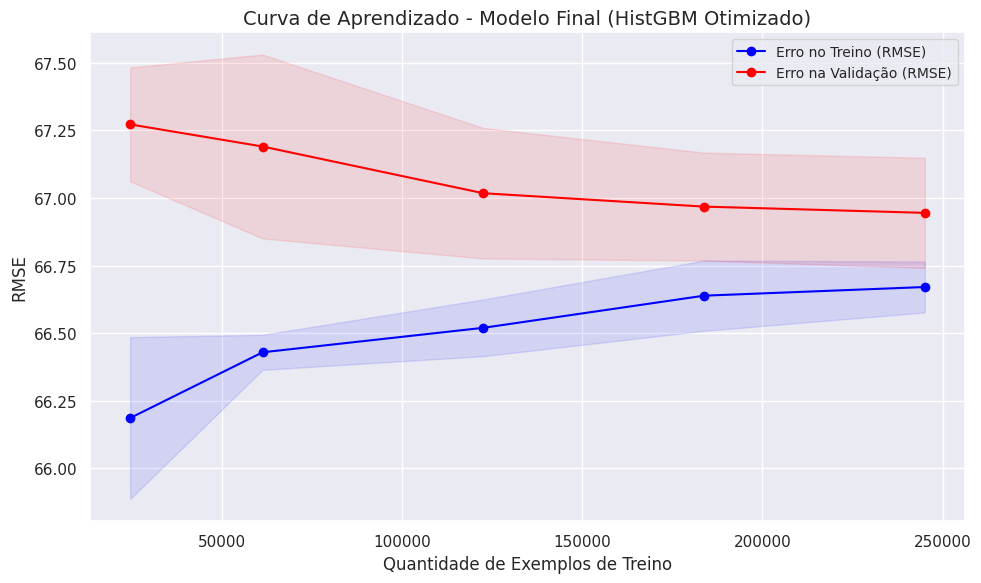

In [ ]:
# ==============================================================================
# 8. AVALIAÇÃO FINAL NO TESTE E CURVA DE APRENDIZADO
# ==============================================================================
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import learning_curve
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

print("="*80)
print("🎯 AVALIAÇÃO FINAL NO CONJUNTO DE TESTE (20% RESERVADOS)")
print("="*80)

# O projeto exige testar no conjunto de Teste: Baseline, Linear Regression sem regularização e a Solução Final
modelos_teste = {
    "Baseline (Média)": Pipeline([('scaler', StandardScaler()), ('dummy', DummyRegressor(strategy='mean'))]),
    "Regressão Linear (S/ Reg)": Pipeline([('scaler', StandardScaler()), ('lr', LinearRegression())]),
    "Solução Final (HistGBM Otimizado)": modelo_final_campeao
}

print(f"{'Modelo':<35} | {'RMSE Teste':<12} | {'MAE Teste':<12} | {'R² Teste':<10} |")
print("-" * 80)

for nome, pipeline_modelo in modelos_teste.items():
    # Treina nos 80% inteiros (desenvolvimento) e prevê nos 20% inéditos (teste)
    pipeline_modelo.fit(X_dev, y_dev)
    preds_teste = pipeline_modelo.predict(X_test)

    rmse_test = np.sqrt(mean_squared_error(y_test, preds_teste))
    mae_test = mean_absolute_error(y_test, preds_teste)
    r2_test = r2_score(y_test, preds_teste)

    print(f"{nome:<35} | {rmse_test:>10,.2f} | {mae_test:>10,.2f} | {r2_test:>8,.4f} |")

print("\n" + "="*80)
print("📈 DIAGNÓSTICO DO AJUSTE: CURVA DE APRENDIZADO OBRIGATÓRIA")
print("="*80)

# Gera a curva de aprendizado usando 10%, 25%, 50%, 75% e 100% dos dados de treino da dobra
train_sizes, train_scores, val_scores = learning_curve(
    estimator=modelo_final_campeao,
    X=X_dev,
    y=y_dev,
    train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0],
    cv=kf,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    random_state=42
)

# Converte os escores negativos para RMSE positivo
train_rmse_mean = -train_scores.mean(axis=1)
train_rmse_std = train_scores.std(axis=1)
val_rmse_mean = -val_scores.mean(axis=1)
val_rmse_std = val_scores.std(axis=1)

# Plot da Curva de Aprendizado
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_rmse_mean, 'o-', color="blue", label="Erro no Treino (RMSE)")
plt.fill_between(train_sizes, train_rmse_mean - train_rmse_std, train_rmse_mean + train_rmse_std, alpha=0.1, color="blue")

plt.plot(train_sizes, val_rmse_mean, 'o-', color="red", label="Erro na Validação (RMSE)")
plt.fill_between(train_sizes, val_rmse_mean - val_rmse_std, val_rmse_mean + val_rmse_std, alpha=0.1, color="red")

plt.title("Curva de Aprendizado - Modelo Final (HistGBM Otimizado)", fontsize=14)
plt.xlabel("Quantidade de Exemplos de Treino", fontsize=12)
plt.ylabel("RMSE", fontsize=12)
plt.legend(loc="best", fontsize=10)
plt.grid(True)
plt.tight_layout()
plt.show()

⏳ Gerando gráficos de resíduos e análise por grupo...


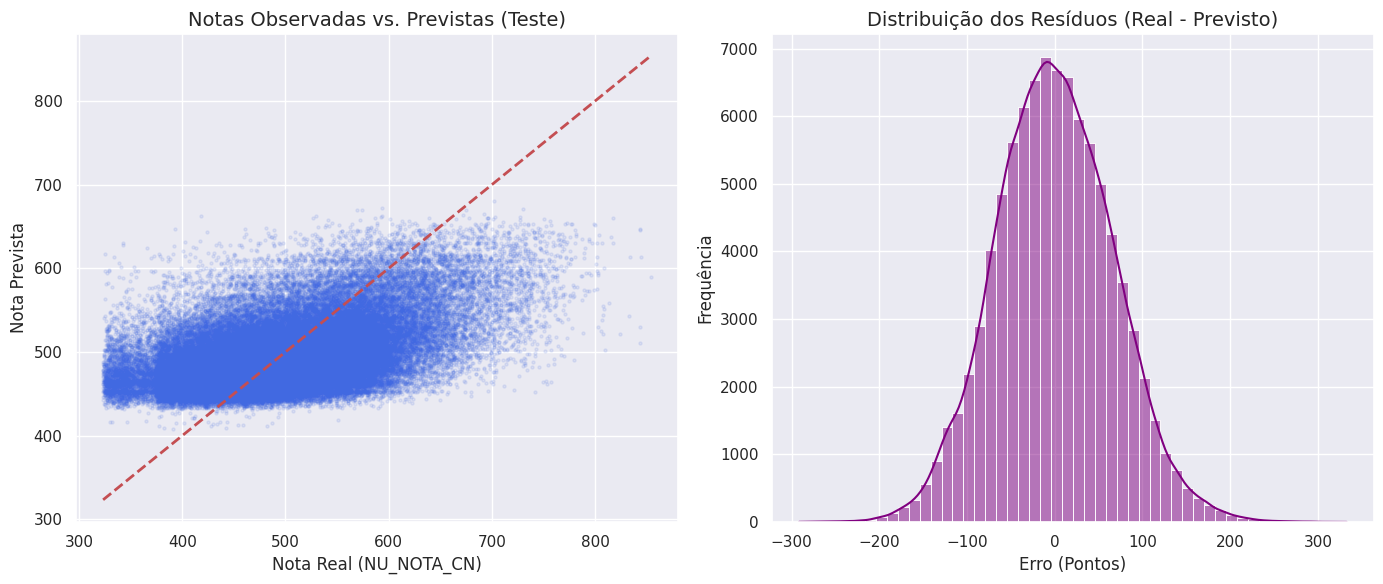


📊 ERRO MÉDIO (RMSE) POR TIPO DE ESCOLA (TP_ESCOLA)
Tipo de Escola  Participantes (N)      RMSE
 Não Respondeu              49774 68.431545
       Pública              36530 62.910300
       Privada               5591 79.756246

⏳ Salvando previsões no arquivo CSV...
✅ Previsões finais salvas com sucesso em './resultados/previsoes_teste.csv'!


In [ ]:
# ==============================================================================
# 9. ANÁLISE DE RESÍDUOS E ERROS POR GRUPO (TP_ESCOLA)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

print("⏳ Gerando gráficos de resíduos e análise por grupo...")

# Garantindo que preds_teste foi calculado na célula anterior
preds_histgbm = modelo_final_campeao.predict(X_test)
residuos = y_test - preds_histgbm

plt.figure(figsize=(14, 6))

# Gráfico 1: Notas Observadas vs. Previstas (Obrigatório)[cite: 14]
plt.subplot(1, 2, 1)
# Usando um scatterplot com baixa opacidade e tamanho reduzido pois são muitos pontos (~92 mil)
plt.scatter(y_test, preds_histgbm, alpha=0.1, s=5, color='royalblue')
# Linha de referência da previsão perfeita
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Notas Observadas vs. Previstas (Teste)', fontsize=14)
plt.xlabel('Nota Real (NU_NOTA_CN)', fontsize=12)
plt.ylabel('Nota Prevista', fontsize=12)

# Gráfico 2: Distribuição dos Resíduos[cite: 14]
plt.subplot(1, 2, 2)
sns.histplot(residuos, bins=50, kde=True, color='purple')
plt.title('Distribuição dos Resíduos (Real - Previsto)', fontsize=14)
plt.xlabel('Erro (Pontos)', fontsize=12)
plt.ylabel('Frequência', fontsize=12)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# ANÁLISE DE ERROS POR GRUPO (TP_ESCOLA) OBRIGATÓRIA
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print("📊 ERRO MÉDIO (RMSE) POR TIPO DE ESCOLA (TP_ESCOLA)")
print("="*80)

# Para analisar por escola no teste, precisamos buscar os dados originais no df_limpo
# usando o index do X_test (já que as features de escola foram removidas no df_features)
df_teste_completo = df_limpo.loc[X_test.index].copy()
df_teste_completo['Previsao_HistGBM'] = preds_histgbm
df_teste_completo['Residuo'] = df_teste_completo['NU_NOTA_CN'] - df_teste_completo['Previsao_HistGBM']

# Dicionário do ENEM para tipos de escola (1: Não Respondeu, 2: Pública, 3: Privada, 4: Exterior)
dic_escola = {1.0: 'Não Respondeu', 2.0: 'Pública', 3.0: 'Privada', 4.0: 'Exterior', 'Ausente': 'Ausente'}
df_teste_completo['TP_ESCOLA_DESC'] = df_teste_completo['TP_ESCOLA'].map(dic_escola).fillna('Desconhecido')

# Calcula o RMSE para cada grupo de escola[cite: 14]
resultados_escola = []
for escola, grupo in df_teste_completo.groupby('TP_ESCOLA_DESC'):
    rmse_grupo = np.sqrt(mean_squared_error(grupo['NU_NOTA_CN'], grupo['Previsao_HistGBM']))
    resultados_escola.append({
        'Tipo de Escola': escola,
        'Participantes (N)': len(grupo),
        'RMSE': rmse_grupo
    })

df_rmse_escola = pd.DataFrame(resultados_escola).sort_values(by='Participantes (N)', ascending=False)
print(df_rmse_escola.to_string(index=False))

# Salva o arquivo de previsões no formato exigido no item 5 do documento do projeto
print("\n⏳ Salvando previsões no arquivo CSV...")

# Busca o NU_INSCRICAO diretamente do dataframe original (df) usando os índices do teste
df_previsoes = pd.DataFrame(index=X_test.index)
df_previsoes['NU_INSCRICAO'] = df.loc[X_test.index, 'NU_INSCRICAO']
df_previsoes['Nota_Real'] = y_test
df_previsoes['Previsao_HistGBM'] = preds_histgbm
df_previsoes['Previsao_Baseline'] = modelos_teste["Baseline (Média)"].predict(X_test)

import os
os.makedirs('./resultados', exist_ok=True)
df_previsoes.to_csv('./resultados/previsoes_teste.csv', index=False)
print("✅ Previsões finais salvas com sucesso em './resultados/previsoes_teste.csv'!")